In [128]:
import solarpy
import pvlib
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import numpy as np

# Measurement data

In [129]:
start_date = '2026-11-03'
end_date = '2026-11-07'

dmi_data, dmi_meta = solarpy.iotools.get_dmi_metobs(station = '06056',
                                          start='2025-11-03',
                                          end='2026-11-05',
                                          parameters = ['ghi'])

#### Find extra-terrestrial radiation and solar position

In [130]:
solarposition = pvlib.solarposition.get_solarposition(
    time=dmi_data.index, latitude=dmi_meta['latitude'], longitude=dmi_meta['longitude'],
)

dmi_data['solar_zenith'] = solarposition['apparent_zenith']
dmi_data['solar_azimuth'] = solarposition['azimuth']

dni_extra = pvlib.irradiance.get_extra_radiation(dmi_data.index)
cos_sza = np.cos(np.deg2rad(solarposition["apparent_zenith"])).clip(lower=0)
dmi_data['ghi_extra'] = dni_extra * cos_sza

print(dmi_data.head(20))


parameterId                ghi  solar_zenith  solar_azimuth  ghi_extra
timestamp                                                             
2025-11-03 00:00:00+00:00  0.0    137.553622      18.448747        0.0
2025-11-03 00:10:00+00:00  0.0    137.077933      21.939828        0.0
2025-11-03 00:20:00+00:00  0.0    136.524660      25.372620        0.0
2025-11-03 00:30:00+00:00  0.0    135.897149      28.741226        0.0
2025-11-03 00:40:00+00:00  0.0    135.199001      32.041038        0.0
2025-11-03 00:50:00+00:00  0.0    134.434003      35.268702        0.0
2025-11-03 01:00:00+00:00  0.0    133.606060      38.422055        0.0
2025-11-03 01:10:00+00:00  0.0    132.719128      41.500025        0.0
2025-11-03 01:20:00+00:00  0.0    131.777170      44.502509        0.0
2025-11-03 01:30:00+00:00  0.0    130.784102      47.430254        0.0
2025-11-03 01:40:00+00:00  0.0    129.743764      50.284724        0.0
2025-11-03 01:50:00+00:00  0.0    128.659893      53.067974        0.0
2025-1

#### Check BSRN limits

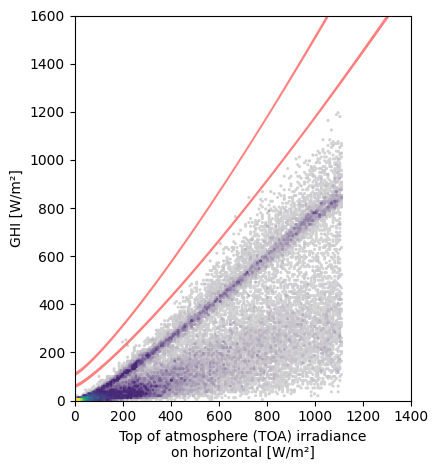

In [131]:
fig, axes = solarpy.plotting.plot_bsrn_limits(
    irradiance=dmi_data['ghi'],
    component="ghi",
    ghi_extra= dmi_data['ghi_extra'],
)
fig.tight_layout()
# fig.savefig(f"results/measurement_data/ghi_bsrn_limits_{start_date}_{end_date}.png", dpi=300)

#### Checking shading

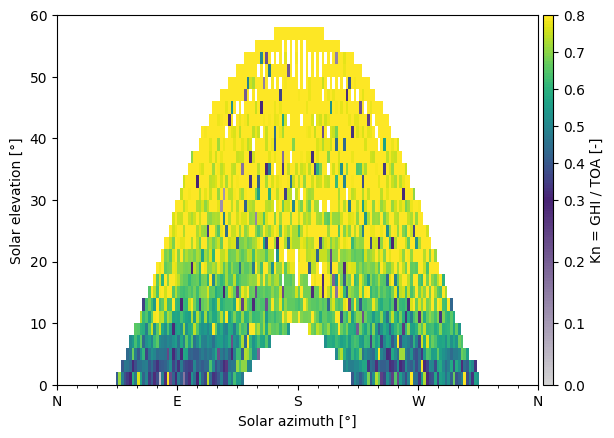

In [132]:
fig, ax = solarpy.plotting.plot_shading_heatmap(
    value=dmi_data["ghi"] / dmi_data["ghi_extra"],
    solar_azimuth=dmi_data["solar_azimuth"],
    solar_elevation=90-dmi_data["solar_zenith"],
    azimuth_bin_size = 2,
    elevation_bin_size = 2,
    cmap=solarpy.plotting.two_part_colormap(),
    norm=TwoSlopeNorm(vmin=0, vcenter=0.3, vmax=0.8),
    colorbar_label="Kn = GHI / TOA [-]",
)
fig.tight_layout()
# fig.savefig(f"results/measurement_data/ghi_shading_heatmap_{start_date}_{end_date}.png", dpi=300)

#### Checking intraday heatmap

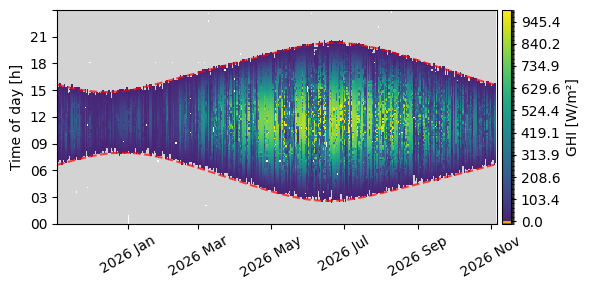

In [133]:

# Load custom colormap and norm
cmap, norm = solarpy.plotting.irradiance_colormap_and_norm(vmax=1000)

fig, ax = plt.subplots(figsize=(6, 3))

_ = solarpy.plotting.plot_intraday_heatmap(
    time=dmi_data.index,
    values=dmi_data["ghi"],
    cmap=cmap,
    norm=norm,
    colorbar_label="GHI [W/m²]",
    ax=ax,  # pass in existing axes
)

# Overlay sunrise and sunset times
sun_rise_set = pvlib.solarposition.sun_rise_set_transit_spa(
    pd.date_range(dmi_data.index.min(), dmi_data.index.max(), freq="1d"),
    dmi_meta["latitude"],
    dmi_meta["longitude"],
)

sunrise = (
    sun_rise_set["sunrise"] - sun_rise_set["sunrise"].index.normalize()
).dt.total_seconds() / 3600

sunset = (
    sun_rise_set["sunset"] - sun_rise_set["sunset"].index.normalize()
).dt.total_seconds() / 3600


ax.plot(sunrise, c="r", linestyle="dashed", lw=1.5, alpha=0.7)
ax.plot(sunset, c="r", linestyle="dashed", lw=1.5, alpha=0.7)

fig.tight_layout()
# fig.savefig(f"results/measurement_data/ghi_intraday_heatmap_{start_date}_{end_date}.png", dpi=300)

#### Resampling in hourly resolution

In [134]:
dmi_data = dmi_data.resample("1h", closed="right", label="right").mean()
print(dmi_data.head(20))

parameterId                       ghi  solar_zenith  solar_azimuth   ghi_extra
timestamp                                                                     
2025-11-03 00:00:00+00:00    0.000000    137.553622      18.448747    0.000000
2025-11-03 01:00:00+00:00    0.000000    135.456468      30.297578    0.000000
2025-11-03 02:00:00+00:00    0.000000    130.203359      48.761337    0.000000
2025-11-03 03:00:00+00:00    0.000000    123.300032      64.708110    0.000000
2025-11-03 04:00:00+00:00    0.000000    115.458555      78.723245    0.000000
2025-11-03 05:00:00+00:00    0.000000    107.227780      91.544364    0.000000
2025-11-03 06:00:00+00:00    0.000000     99.039966     103.827640    0.000000
2025-11-03 07:00:00+00:00    4.500000     91.060798     116.110656   12.446112
2025-11-03 08:00:00+00:00   56.333333     84.148190     128.817554  141.534645
2025-11-03 09:00:00+00:00  142.500000     78.436256     142.241387  278.324098
2025-11-03 10:00:00+00:00  135.833333     74.251439 

# Forecast data

In [135]:
forecast_data = pd.read_csv('data/06056_20261103T1500.csv', index_col=0, parse_dates=True)
forecast_data.head()

,dmi_harmonie_arome_europe,metno_nordic,ecmwf_ifs025,ecmwf_aifs025_single,gfs_global,ecmwf_ifs,dmi_seamless,gfs_seamless
date,,,,,,,,
2026-11-03 00:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-03 01:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-03 02:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-03 03:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-03 04:00:00+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Plotting the forecast data

NB: Husk!!! At det measured data skal overlappe med forecast dataet for at nedenstående kan laves

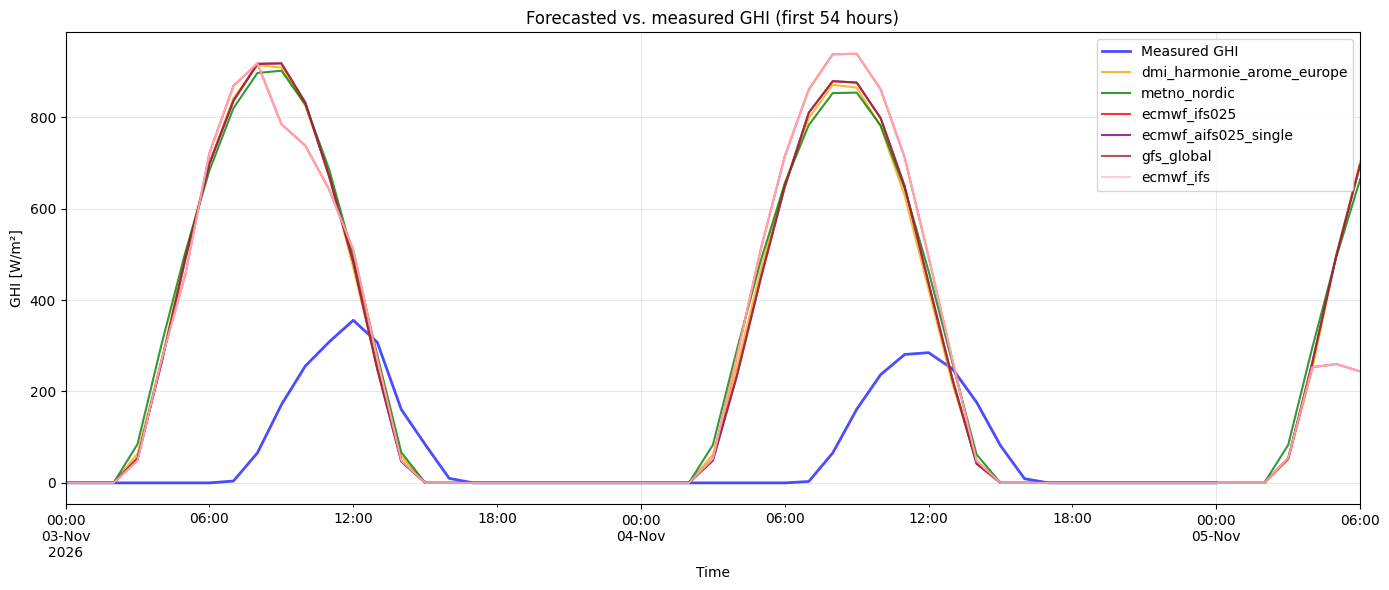

In [136]:
# Plotting the forecast data against the measured data

col_names = ['dmi_harmonie_arome_europe', 'metno_nordic', 'ecmwf_ifs025',
             'ecmwf_aifs025_single', 'gfs_global', 'ecmwf_ifs', 'dmi_seamless', 'gfs_seamless']
            
colors = ['orange', 'green', 'red', 'purple', 'brown', 'pink', 'cyan', 'magenta']

# Restrict to the first 54 hours of the forecast
start = forecast_data.index[0]
end = start + pd.Timedelta(hours=54)
fc = forecast_data.loc[start:end]
measured = dmi_data['ghi'].loc[start:end]


fig, ax = plt.subplots(figsize=(14, 6))

measured.plot(ax=ax, label='Measured GHI', color='blue', alpha=0.7, linewidth=2)

for name, color in zip(col_names, colors):
    fc[name].plot(ax=ax, label=name, color=color, alpha=0.8)

ax.set_xlabel('Time')
ax.set_ylabel('GHI [W/m²]')
ax.set_title('Forecasted vs. measured GHI (first 54 hours)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
#plt.savefig('forecast_vs_measured_ghi_3_nov_54hours.png', dpi=300)

#### Calculating Root Mean Square Error for the 54 horizon

Forecast rows: 55
Measured values: 49
Missing measurements: 6


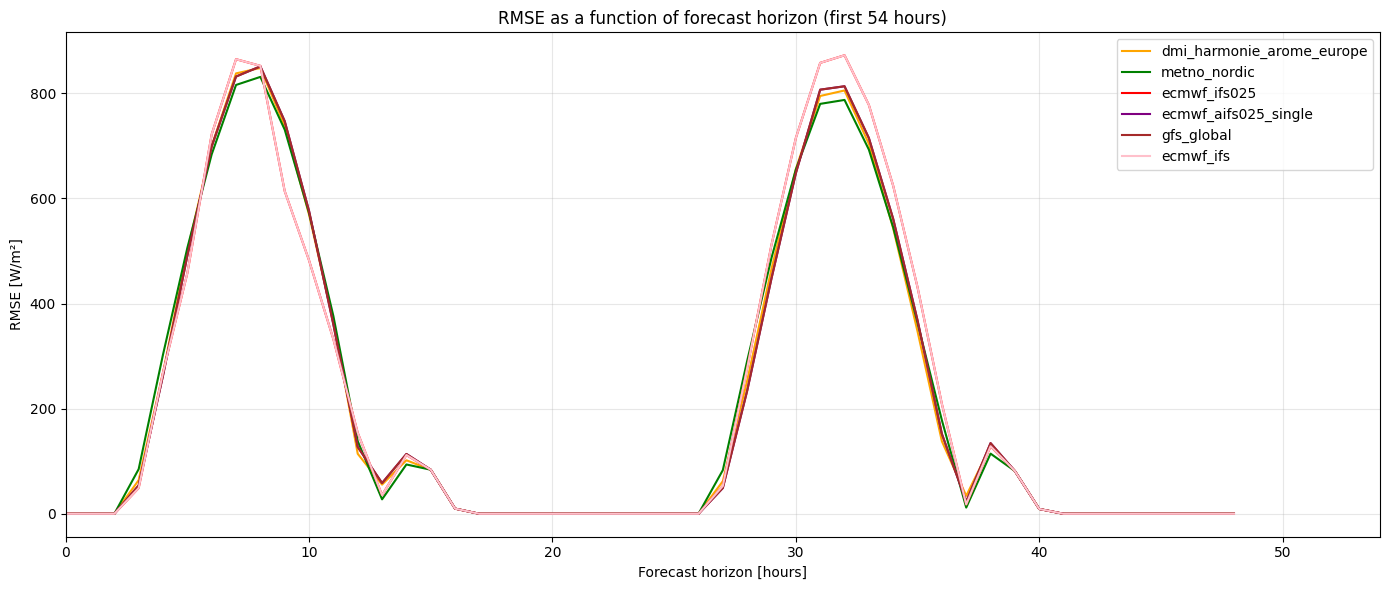

In [137]:
# Restrict to forecast horizons 0–54
start = forecast_data_w9.index[0]
end = start + pd.Timedelta(hours=54)

fc = forecast_data_w9.loc[start:end].copy()

# Select measurements matching forecast timestamps
measured = dmi_data['ghi'].reindex(fc.index)

# Define forecast horizons
fc['forecast_horizon'] = np.arange(len(fc))

# Check data
print("Forecast rows:", len(fc))
print("Measured values:", measured.notna().sum())
print("Missing measurements:", measured.isna().sum())

# Plot
fig, ax = plt.subplots(figsize=(14, 6))

for name, color in zip(col_names, colors):

    squared_error = (measured - fc[name])**2

    rmse_by_horizon = np.sqrt(
        squared_error.groupby(fc['forecast_horizon']).mean()
    )

    ax.plot(
        rmse_by_horizon.index,
        rmse_by_horizon.values,
        label=name,
        color=color
    )

ax.set_xlabel('Forecast horizon [hours]')
ax.set_ylabel('RMSE [W/m²]')
ax.set_title('RMSE as a function of forecast horizon (first 54 hours)')
ax.set_xlim(0, 54)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()